# Speech Emotion Recognition (RAVDESS)

Reconocimiento de emociones en habla. La lógica reutilizable vive en `src/`; este notebook orquesta.

## Imports y setup

In [1]:
import sys, os
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
%load_ext autoreload
%autoreload 2

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier

from src import config
from src.data import build_metadata, get_xy
from src.splits import make_split, load_split, assign_split
from src.features.egemaps import extract_egemaps
from src.features.wav2vec import extract_wav2vec, extract_wav2vec_layers
from src.evaluation import grouped_cv
from src.metrics import evaluate
from src.plots import plot_confusion_matrix

# Constantes compartidas
sns.set_theme(style="whitegrid", context="notebook")
REPORTS_DIR = Path("reports"); REPORTS_DIR.mkdir(exist_ok=True)
META_COLS = config.META_COLS
EMOTION_ORDER = ["neutral", "calm", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

## Datos y split

Metadata de los 2452 audios + split train/val congelado **por hablante** (speaker-independent, evita data leakage).

In [2]:
metadata = build_metadata()

# Split por hablante, congelado en splits/split.json (se reusa si ya existe)
split = load_split() if config.SPLIT_PATH.exists() else make_split(metadata)
metadata = assign_split(metadata, split)

print(metadata.shape, "| val_actors:", split["val_actors"])
metadata.head()

(2452, 10) | val_actors: [2, 9, 11, 20]


,path,modality,vocal_channel,emotion,intensity,statement,repetition,actor,gender,split
0,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,1,1,male,train
1,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,kids,2,1,male,train
2,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,1,1,male,train
3,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,neutral,normal,dogs,2,1,male,train
4,/Users/bautygarcia/projects/tp-final-ml/data/A...,audio-only,speech,calm,normal,kids,1,1,male,train


## eGeMAPS

88 features expertas (OpenSMILE), cacheadas; dataset combinado metadata + features.

In [3]:
egemaps_path = config.PROCESSED_DIR / "egemaps.parquet"
if egemaps_path.exists():
    egemaps = pd.read_parquet(egemaps_path)
else:
    egemaps = extract_egemaps(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    egemaps.to_parquet(egemaps_path)

# Dataset combinado: metadata (con split) + 88 features
dataset = metadata.merge(egemaps, left_on="path", right_index=True, how="left")
dataset.to_parquet(config.PROCESSED_DIR / "dataset.parquet")
print("eGeMAPS:", egemaps.shape, "| dataset:", dataset.shape)

eGeMAPS: (2452, 88) | dataset: (2452, 98)


## wav2vec

Embeddings SSL (`wav2vec2-base`, 768-dim, mean-pooled), cacheados; dataset combinado.

In [4]:
w2v_path = config.PROCESSED_DIR / "wav2vec.parquet"
if w2v_path.exists():
    wav2vec = pd.read_parquet(w2v_path)
else:
    wav2vec = extract_wav2vec(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    wav2vec.to_parquet(w2v_path)

dataset_w2v = metadata.merge(wav2vec, left_on="path", right_index=True, how="left")
dataset_w2v.to_parquet(config.PROCESSED_DIR / "dataset_wav2vec.parquet")
print("wav2vec:", wav2vec.shape, "| dataset_wav2vec:", dataset_w2v.shape)

wav2vec: (2452, 768) | dataset_wav2vec: (2452, 778)


# EDA

Exploración de clases y features (sobre speech).

In [5]:
speech = dataset[dataset["vocal_channel"] == "speech"].copy()
FEAT_COLS = [c for c in dataset.columns if c not in META_COLS]

## Balance de clases

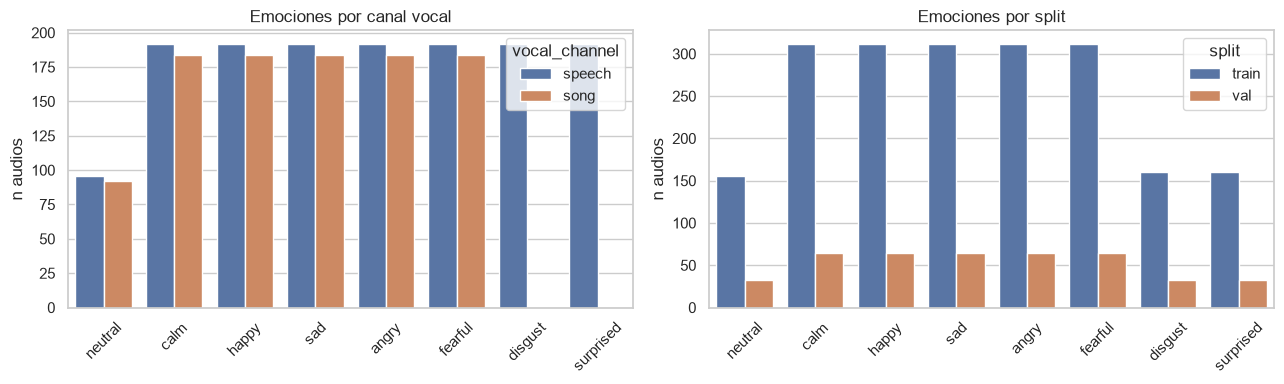

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=dataset, x="emotion", hue="vocal_channel", order=EMOTION_ORDER, ax=axes[0])
axes[0].set_title("Emociones por canal vocal"); axes[0].set_xlabel(""); axes[0].set_ylabel("n audios"); axes[0].tick_params(axis="x", rotation=45)
sns.countplot(data=dataset, x="emotion", hue="split", order=EMOTION_ORDER, ax=axes[1])
axes[1].set_title("Emociones por split"); axes[1].set_xlabel(""); axes[1].set_ylabel("n audios"); axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_class_balance.png", dpi=110, bbox_inches="tight"); plt.show()

## Distribuciones por emoción (speech)

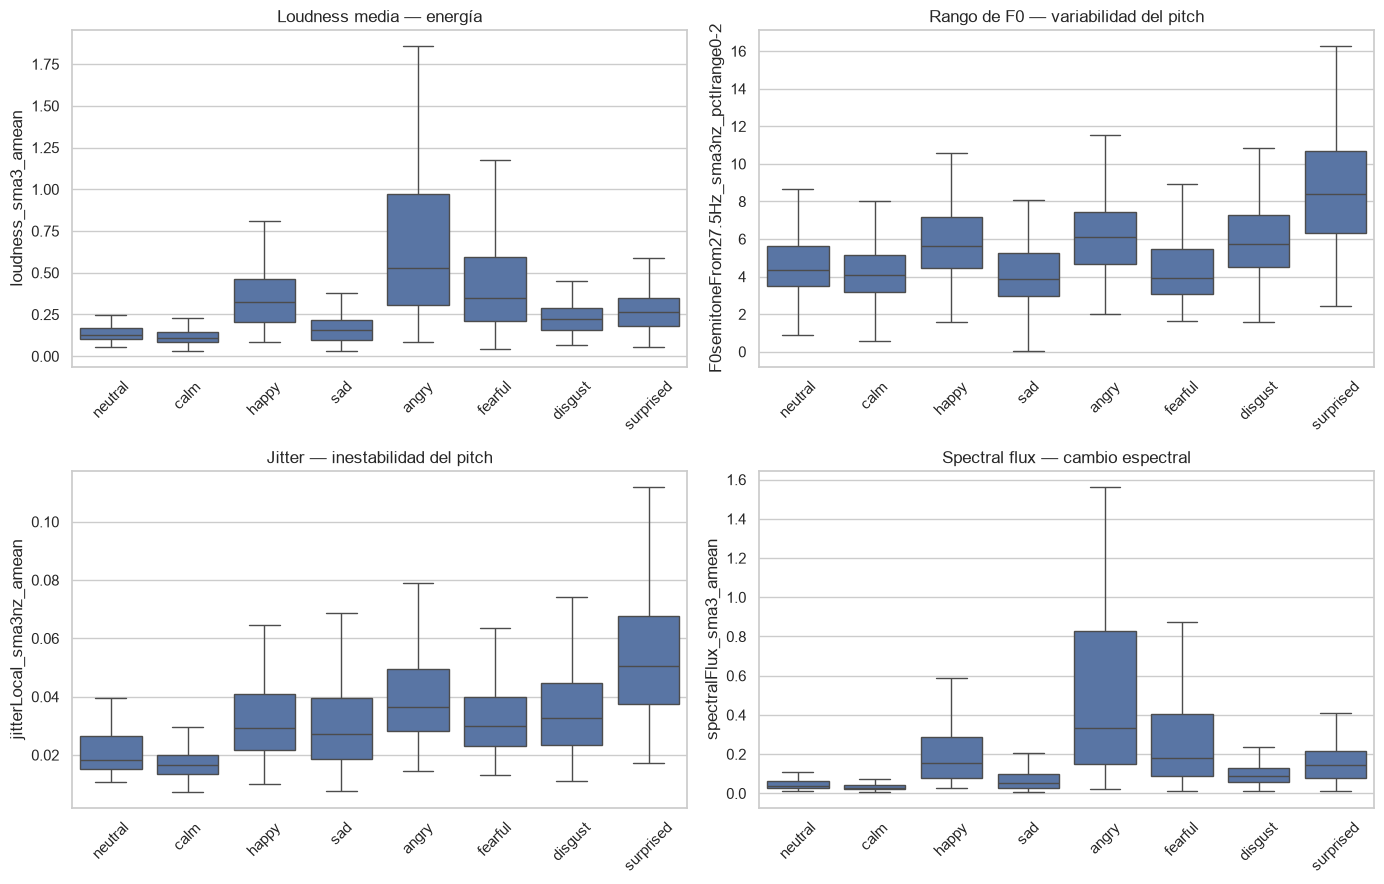

In [7]:
top_feats = [
    ("loudness_sma3_amean", "Loudness media — energía"),
    ("F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2", "Rango de F0 — variabilidad del pitch"),
    ("jitterLocal_sma3nz_amean", "Jitter — inestabilidad del pitch"),
    ("spectralFlux_sma3_amean", "Spectral flux — cambio espectral"),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (feat, title) in zip(axes.ravel(), top_feats):
    sns.boxplot(data=speech, x="emotion", y=feat, order=EMOTION_ORDER, ax=ax, showfliers=False)
    ax.set_title(title); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_feature_dists.png", dpi=110, bbox_inches="tight"); plt.show()

## PCA 2D por emoción (speech)

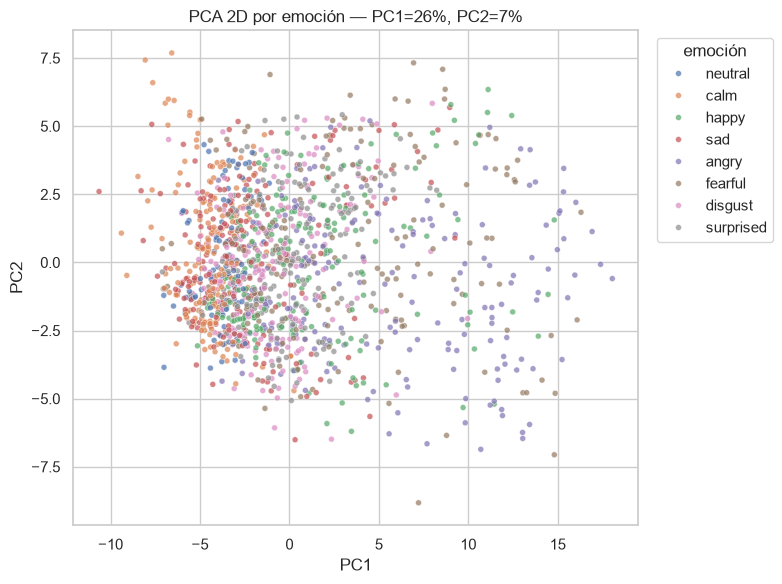

In [8]:
X_pca = np.clip(RobustScaler().fit_transform(speech[FEAT_COLS]), -5, 5)
pca = PCA(n_components=2, random_state=config.RANDOM_SEED).fit(X_pca)
pcs = pca.transform(X_pca)
speech["PC1"], speech["PC2"] = pcs[:, 0], pcs[:, 1]
var = pca.explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="emotion", hue_order=EMOTION_ORDER, s=18, alpha=0.7, ax=ax)
ax.set_title(f"PCA 2D por emoción — PC1={var[0]:.0f}%, PC2={var[1]:.0f}%")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="emoción")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_pca_emotion.png", dpi=110, bbox_inches="tight"); plt.show()

## Confound: género

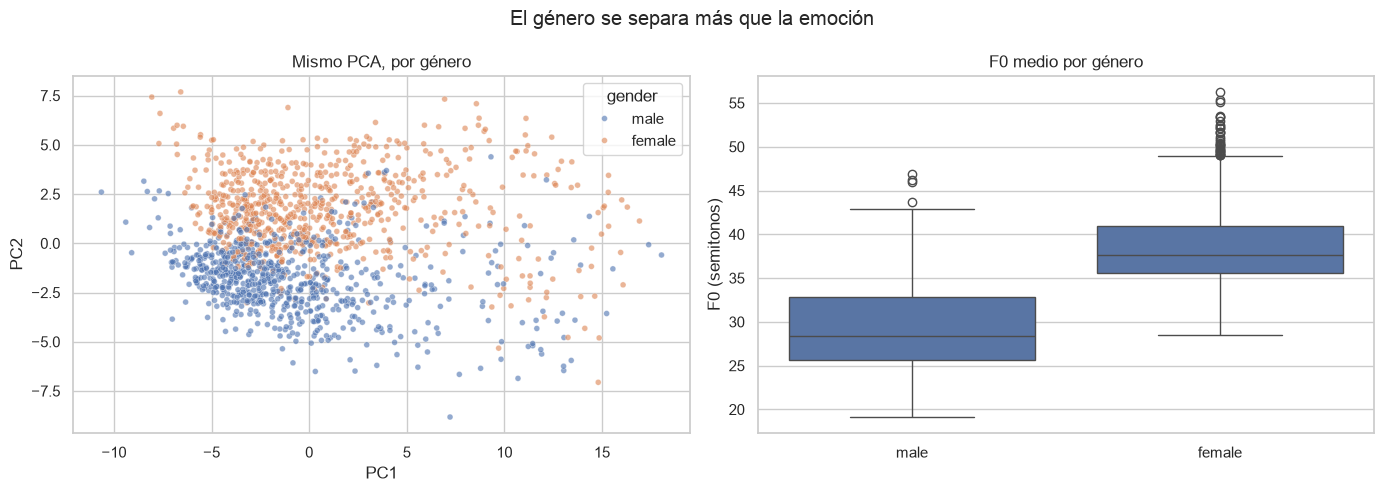

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=speech, x="PC1", y="PC2", hue="gender", s=18, alpha=0.6, ax=axes[0])
axes[0].set_title("Mismo PCA, por género")
sns.boxplot(data=speech, x="gender", y="F0semitoneFrom27.5Hz_sma3nz_amean", ax=axes[1])
axes[1].set_title("F0 medio por género"); axes[1].set_xlabel(""); axes[1].set_ylabel("F0 (semitonos)")
fig.suptitle("El género se separa más que la emoción")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "eda_confound_gender.png", dpi=110, bbox_inches="tight"); plt.show()

# Modelos — comparación

Mismo CV por hablante (GroupKFold por actor) sobre las 3 representaciones. Los modelos lineales escalan con StandardScaler dentro de cada fold; RF no lo necesita. Chance = 12.5%.

In [10]:
# Representaciones (speech-only). wav2vec.parquet ya es la capa 8.
Xe, y, groups = get_xy(dataset, vocal_channel="speech")          # eGeMAPS 88
Xw, _, _      = get_xy(dataset_w2v, vocal_channel="speech")      # wav2vec capa 8, 768
Xc = pd.concat([Xe.reset_index(drop=True), Xw.reset_index(drop=True)], axis=1)   # combinado 856
reps = {"eGeMAPS (88)": Xe, "wav2vec-c8 (768)": Xw, "combinado (856)": Xc}

def scaled(m):
    return make_pipeline(StandardScaler(), m)

models = {
    "RandomForest": RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1),
    "LogReg":       scaled(LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced")),
    "LinearSVC":    scaled(LinearSVC(C=0.1, class_weight="balanced", max_iter=5000)),
    "SVM-RBF":      scaled(SVC(C=10, gamma="scale", class_weight="balanced")),
    "HistGB":       HistGradientBoostingClassifier(random_state=config.RANDOM_SEED, class_weight="balanced"),
    "kNN":          scaled(KNeighborsClassifier(n_neighbors=25)),
}

# Tabla cacheada (el SVM es lento); si no existe, se computa y se guarda
comp_path = config.PROCESSED_DIR / "model_comparison.parquet"
if comp_path.exists():
    table = pd.read_parquet(comp_path)
else:
    macro = {}
    for mn, model in models.items():
        for rn, X in reps.items():
            oof, _ = grouped_cv(model, X, y, groups, n_splits=5)
            macro[(mn, rn)] = evaluate(y, oof, labels=EMOTION_ORDER)["macro_f1"]
    table = pd.Series(macro).unstack().reindex(index=list(models), columns=list(reps)).round(3)
    table.to_parquet(comp_path)
table

,eGeMAPS (88),wav2vec-c8 (768),combinado (856)
RandomForest,0.449,0.576,0.582
LogReg,0.511,0.715,0.721
LinearSVC,0.507,0.674,0.679
SVM-RBF,0.471,0.686,0.692
HistGB,0.472,0.608,0.623
kNN,0.396,0.504,0.519


## Matriz de confusión del mejor modelo

Mejor: LogReg / combinado (856) -> 0.721


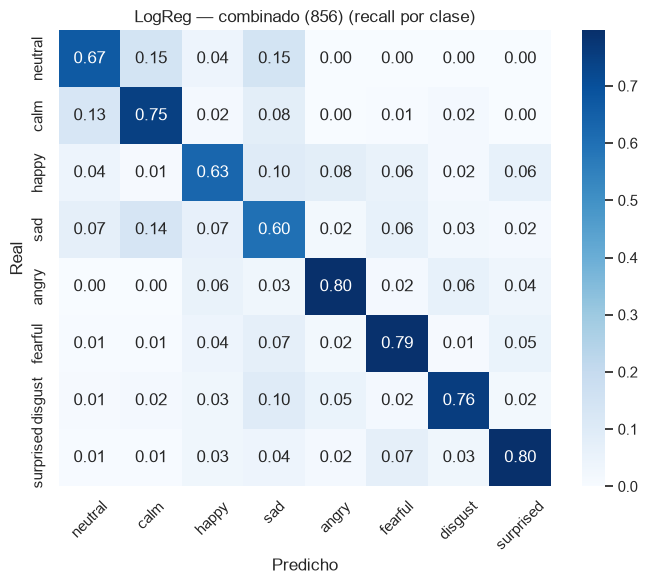

In [11]:
bm, br = table.stack().idxmax()
print("Mejor:", bm, "/", br, "->", round(table.loc[bm, br], 3))
oof_best, _ = grouped_cv(models[bm], reps[br], y, groups, n_splits=5)
fig, ax = plot_confusion_matrix(y, oof_best, labels=EMOTION_ORDER, normalize="true",
                                title=f"{bm} — {br} (recall por clase)")
ax.tick_params(axis="x", rotation=45); fig.tight_layout()
fig.savefig(REPORTS_DIR / "best_model_confusion.png", dpi=110, bbox_inches="tight"); plt.show()

# Investigación — capas de wav2vec

¿Qué capa da mejores features para emoción? El último hidden state está sesgado al objetivo de
pre-entrenamiento; la info prosódica/emocional suele estar en capas intermedias. Probamos el
mean-pool de **cada** capa + el mismo RF (GroupKFold por actor, speech-only).

In [12]:
# Embeddings de las 13 capas (cache .npz)
layers_path = config.PROCESSED_DIR / "wav2vec_layers.npz"
if layers_path.exists():
    _npz = np.load(layers_path, allow_pickle=True)
    layer_emb, layer_paths = _npz["emb"], [str(p) for p in _npz["paths"]]
else:
    layer_emb, layer_paths = extract_wav2vec_layers(metadata)
    config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(layers_path, emb=layer_emb, paths=np.array(layer_paths, dtype=object))
assert layer_paths == metadata["path"].tolist()

# Barrido: RF por capa (cache parquet)
sweep_path = config.PROCESSED_DIR / "wav2vec_layer_sweep.parquet"
if sweep_path.exists():
    sweep = pd.read_parquet(sweep_path)
else:
    mask = (metadata["vocal_channel"] == "speech").to_numpy()
    ys, gs = metadata.loc[mask, "emotion"], metadata.loc[mask, "actor"]
    rows = []
    for l in range(layer_emb.shape[1]):
        rf_l = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=config.RANDOM_SEED, n_jobs=-1)
        oof_l, _ = grouped_cv(rf_l, layer_emb[mask, l, :], ys, gs, n_splits=5)
        m = evaluate(ys, oof_l, labels=EMOTION_ORDER)
        rows.append({"layer": l, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"]})
    sweep = pd.DataFrame(rows)
    sweep.to_parquet(sweep_path)
sweep

,layer,accuracy,macro_f1
0,0,0.472222,0.461267
1,1,0.497222,0.480091
2,2,0.529861,0.513858
3,3,0.538889,0.522706
4,4,0.555556,0.538875
5,5,0.584722,0.570671
6,6,0.592361,0.575530
7,7,0.588194,0.574737
8,8,0.592361,0.578493
9,9,0.552083,0.536499


## Macro-F1 según la capa

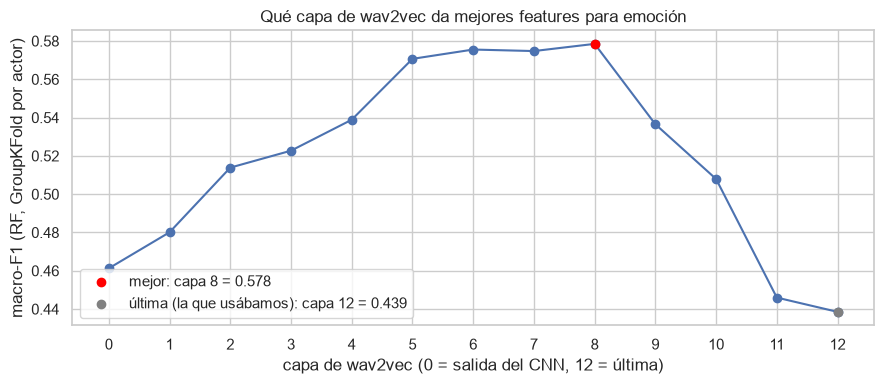

In [13]:
best = sweep.loc[sweep["macro_f1"].idxmax()]
last = sweep.iloc[-1]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(sweep["layer"], sweep["macro_f1"], marker="o")
ax.scatter([best["layer"]], [best["macro_f1"]], color="red", zorder=5,
           label=f"mejor: capa {int(best['layer'])} = {best['macro_f1']:.3f}")
ax.scatter([last["layer"]], [last["macro_f1"]], color="gray", zorder=5,
           label=f"última (la que usábamos): capa {int(last['layer'])} = {last['macro_f1']:.3f}")
ax.set_xlabel("capa de wav2vec (0 = salida del CNN, 12 = última)")
ax.set_ylabel("macro-F1 (RF, GroupKFold por actor)")
ax.set_title("Qué capa de wav2vec da mejores features para emoción")
ax.set_xticks(range(len(sweep))); ax.legend()
fig.tight_layout(); fig.savefig(REPORTS_DIR / "wav2vec_layer_sweep.png", dpi=110, bbox_inches="tight"); plt.show()

# Investigación — feature engineering

Qué features importan y si conviene seleccionarlas/decorrelacionarlas (RF, speech-only). Cómputo cacheado.

## Importancia de features

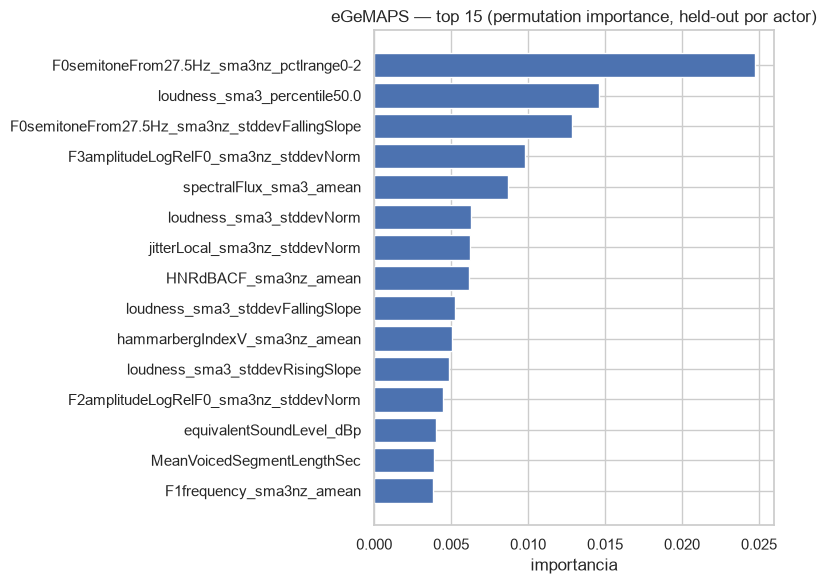

Contribución en el RF combinado -> eGeMAPS: 16.6% | wav2vec: 83.4%


In [14]:
imp = pd.read_parquet(config.PROCESSED_DIR / "egemaps_perm_importance.parquet")
contrib = json.load(open(config.PROCESSED_DIR / "contribution.json"))

fig, ax = plt.subplots(figsize=(8, 6))
top15 = imp.head(15).iloc[::-1]
ax.barh(top15["feature"], top15["importance"])
ax.set_title("eGeMAPS — top 15 (permutation importance, held-out por actor)")
ax.set_xlabel("importancia")
fig.tight_layout(); fig.savefig(REPORTS_DIR / "egemaps_importance.png", dpi=110, bbox_inches="tight"); plt.show()

print(f"Contribución en el RF combinado -> eGeMAPS: {contrib['egemaps_share']:.1%} | wav2vec: {contrib['wav2vec_share']:.1%}")

## Feature selection (top-k)

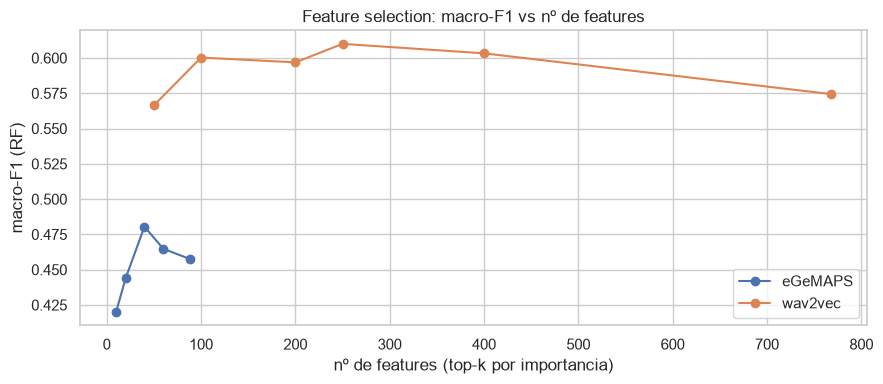

rep,eGeMAPS,wav2vec
k,,
10,0.4201,NaN
20,0.4438,NaN
40,0.4805,NaN
50,NaN,0.5664
60,0.4648,NaN
88,0.4576,NaN
100,NaN,0.6003
200,NaN,0.5969
250,NaN,0.6100


In [15]:
fs = pd.read_parquet(config.PROCESSED_DIR / "feature_selection.parquet")
fig, ax = plt.subplots(figsize=(9, 4))
for rep, g in fs.groupby("rep"):
    ax.plot(g["k"], g["macro_f1"], marker="o", label=rep)
ax.set_xlabel("nº de features (top-k por importancia)"); ax.set_ylabel("macro-F1 (RF)")
ax.set_title("Feature selection: macro-F1 vs nº de features"); ax.legend()
fig.tight_layout(); fig.savefig(REPORTS_DIR / "feature_selection.png", dpi=110, bbox_inches="tight"); plt.show()
fs.pivot(index="k", columns="rep", values="macro_f1")

## Decorrelación / PCA

In [16]:
corr_stats = json.load(open(config.PROCESSED_DIR / "decorr_corr.json"))
dec = pd.read_parquet(config.PROCESSED_DIR / "decorrelation.parquet")
print("eGeMAPS: pares |r|>0.95 =", corr_stats["egemaps_pairs_gt_0.95"],
      "| |r|>0.90 =", corr_stats["egemaps_pairs_gt_0.90"],
      "| mediana |r| =", round(corr_stats["egemaps_median_abs_r"], 3))
print("wav2vec: pares |r|>0.80 =", corr_stats["wav2vec_pairs_gt_0.80"])
dec

eGeMAPS: pares |r|>0.95 = 27 | |r|>0.90 = 45 | mediana |r| = 0.109
wav2vec: pares |r|>0.80 = 0


,variante,macro_f1
0,eGeMAPS raw (88),0.4486
1,eGeMAPS PCA-95%,0.4527
2,wav2vec raw (768),0.5756
3,wav2vec PCA-90%,0.5902
